# Student time-management mini-survey: descriptive and inferential analysis

**Data:** `data/processed/` (cleaned from the primary survey; 39 respondents, 301 respondent × task reports)
**Tools:** Python 3 · pandas · NumPy · SciPy · Matplotlib (helper code in `src/tmsurvey/`)

## Research questions
1. **Describe** who responded, how they plan, why plans fail, and how task types differ in energy, productivity, satisfaction and timing.
2. **Chronotype.** Does being a morning / evening person relate to productivity, sleep, or the time of day tasks get done?
3. **Planning.** Do planning styles differ in plan adherence, productivity, and interest in a planning app? Is plan adherence linked to productivity?
4. **Task level.** What explains a task's rated productivity and satisfaction (energy, interruptions, importance, plan adherence, sleep, task type)?

## Analytic approach (decided before looking at p-values)
| Issue | Decision |
|---|---|
| Small *n* (39), ordinal 1-5 ratings | Non-parametric tests (Kruskal-Wallis, Mann-Whitney, Spearman); effect sizes and confidence intervals reported, not just *p* |
| Many tests | Holm correction within each pre-defined family; every test is stored in one registry table |
| 301 task rows come from only 39 people (non-independent) | Task-level inference uses **respondent-clustered** standard errors and a **cluster bootstrap**; row-level *p*-values are never used for conclusions |
| Sparse contingency tables | Permutation (Monte-Carlo) chi-square p-value |
| Flagged respondents (2 sleep outliers, 2 straight-liners) | Kept in the main analysis; a sensitivity analysis drops them |
| Sparse variables (`focus_hours`, `times_per_week`) | Described, but excluded from inference |

> The sample is a small, near-balanced **quota-style** sample (13/13/13 chronotypes, 13/13/13 living arrangements, ~10 per academic level), so
> category *percentages* describe this sample and are **not** population prevalences. Comparisons between groups remain valid.

In [1]:
%matplotlib inline
import sys, platform
from pathlib import Path
import numpy as np
import pandas as pd
import scipy
from scipy import stats as sps
import matplotlib
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from tmsurvey import config as C, data, stats as S, plots as P

pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
P.set_style()
C.TABLE_DIR.mkdir(parents=True, exist_ok=True)
C.FIG_DIR.mkdir(parents=True, exist_ok=True)

REG = []   # registry: one row per inferential test, so multiplicity is handled transparently
def register(family, test, outcome, factor, n, stat, df, p, effect, effect_name):
    REG.append(dict(family=family, test=test, outcome=outcome, factor=factor, n=n,
                    statistic=stat, df=df, p=p, effect_size=effect, effect_name=effect_name))

def save_table(df, name):
    df.to_csv(C.TABLE_DIR / f"{name}.csv")
    return df

def show_p(df, cols):
    # display helper: format p-value columns as '< .001' / '.034' (saved CSVs keep full numeric precision)
    d = df.copy()
    for c in cols:
        d[c] = d[c].map(lambda v: S.fmt_p(v).replace("= ", ""))
    return d

print("Project root:", ROOT)

Project root: /home/claude/survey-time-management-analysis


## 1. Data loading and integrity checks
No cleaning is repeated here. The notebook only *verifies* that the cleaned files are internally consistent, so that any
later change to the data fails loudly instead of silently changing results.

In [2]:
r = data.load_respondents()
t = data.load_tasks()
report = data.load_cleaning_report()

# --- structural checks ---------------------------------------------------------------------------------
assert len(r) == 39 and r["row_id"].is_unique, "respondent table should have 39 unique respondents"
assert len(t) == 301 and set(t["row_id"]) <= set(r["row_id"]), "every task row must belong to a respondent"
assert (t.groupby("row_id").size().reindex(r["row_id"]).values == r["n_tasks_done"].values).all(), "n_tasks_done must equal #task rows"
assert t[C.RATINGS].apply(lambda s: s.between(1, 5)).all().all(), "ratings must lie in 1-5"
assert t[C.BLOCKS].isin([0, 1]).all().all(), "time-block flags must be 0/1"

# --- respondent attributes repeated in the task file must agree with the respondent file ---------------
chk = t.merge(r[["row_id", "level", "chronotype", "plan_style", "follow_plan", "sleep_hours"]], on="row_id", suffixes=("", "_r"))
for c in ["level", "chronotype", "plan_style", "follow_plan", "sleep_hours"]:
    assert (chk[c].astype(str) == chk[c + "_r"].astype(str)).all(), f"{c} differs between files"

# --- the Excel workbook and the CSV files hold identical data -------------------------------------------
xl = C.DATA_DIR / "Mini_Survey_cleaned.xlsx"
assert pd.read_excel(xl, sheet_name="respondents").equals(pd.read_csv(C.DATA_DIR / "respondents_clean.csv"))
assert pd.read_excel(xl, sheet_name="tasks_long").equals(pd.read_csv(C.DATA_DIR / "tasks_long_clean.csv"))
print("All integrity checks passed.")
print(f"Respondents: {len(r)}   Task reports: {len(t)}   Median tasks per respondent: {t.groupby('row_id').size().median():.0f}")
report.set_index("item")

All integrity checks passed.
Respondents: 39   Task reports: 301   Median tasks per respondent: 8


,value
item,
rows_raw,40
truly_missing_cells,0
dont_do_this_cells,1013
exact_duplicate_rows,1
duplicates_dropped,1
q13_mixed_fixed,3
stray_cells_removed,70
cells_to_impute,3
cells_imputed,3


In [3]:
miss = pd.concat([r.isna().sum().rename("respondents"), t.isna().sum().rename("tasks")], axis=1).fillna(0).astype(int)
display_miss = miss[(miss > 0).any(axis=1)]
print("Variables with missing values:")
print(display_miss)
print("\nShare of `times_per_week` missing, by task type:")
t.groupby("task_label")["times_per_week"].apply(lambda s: s.isna().mean()).round(2).sort_values(ascending=False)

Variables with missing values:
                respondents  tasks
focus_hours              26      0
times_per_week            0    153

Share of `times_per_week` missing, by task type:


task_label
Work / clubs      0.95
Assignments       0.86
Exercise          0.84
Chores            0.80
Commute           0.74
Classes / labs    0.74
Self-study        0.48
Leisure           0.23
Meals             0.05
Sleep             0.05
Name: times_per_week, dtype: float64

**Reading the missingness.** Only two variables have gaps. `focus_hours` was answered by just 13 of 39 respondents (and 10 of those 13 said 1 hour), and `times_per_week` is missing for 153 of 301 task reports, almost entirely for tasks many people do not do regularly (work/clubs 95%, assignments 86%, exercise 84%) but rarely for sleep or meals (5%).
Because missingness tracks task type, it looks structural (question not applicable / "don't do this", cf. the 1,013 such cells in the cleaning report) rather than random, so these values are **not imputed** and the two variables are described but not used in inference. *(Assumption: confirm against the questionnaire routing.)*

## 2. Descriptive statistics: respondents (n = 39)

In [4]:
desc_r = S.describe_numeric(r, C.RESP_NUMERIC)
save_table(desc_r, "descriptives_respondent_numeric")

,n,missing,mean,sd,median,q1,q3,min,max,skew
variable,,,,,,,,,,
follow_plan,39,0,3.000,1.000,3.0,2.0,4.00,1.0,5.0,0.166
reschedule_freq,39,0,3.205,0.864,3.0,3.0,4.00,2.0,5.0,0.353
overall_productivity,39,0,2.872,1.056,3.0,2.0,3.50,1.0,5.0,0.268
focus_hours,13,26,2.077,2.397,1.0,1.0,1.00,1.0,9.0,2.469
wake_h,39,0,7.282,1.621,7.0,6.0,8.00,4.5,11.0,0.594
bed_h_night,39,0,24.282,1.455,24.5,23.0,25.25,22.0,28.0,0.506
sleep_hours,39,0,7.000,0.811,7.0,6.5,7.50,5.0,8.5,-0.429
n_tasks_done,39,0,7.718,1.503,8.0,7.0,8.50,3.0,10.0,-0.763


In [5]:
cat_cols = ["age_group", "level", "living", "chronotype", "plan_style", "peak_time", "schedule_first",
            "most_postponed", "wish_better", "app_interest"]
freq = pd.concat({c: S.freq_table(r[c]) for c in cat_cols}, names=["variable", "category"])
save_table(freq, "descriptives_respondent_categorical")
freq.round(1)

n   pct  ci_low  ci_high
variable       category                                                       
age_group      18-20                                 11  28.2    16.5     43.8
               21-23                                 15  38.5    24.9     54.1
               24-26                                  8  20.5    10.8     35.5
               27 or above                            5  12.8     5.6     26.7
level          Undergraduate Year 1-2                10  25.6    14.6     41.1
               Undergraduate Year 3+                 10  25.6    14.6     41.1
               Master's                               9  23.1    12.6     38.3
               PhD / Research scholar                10  25.6    14.6     41.1
living         With family                           13  33.3    20.6     49.0
               Hostel                                13  33.3    20.6     49.0
               Rented flat / PG                      13  33.3    20.6     49.0
chronotype     Morning person                        13  33.3    20.6     49.0
               No clear preference                   13  33.3    20.6     49.0
               Evening / night person                13  33.3    20.6     49.0
plan_style     I do not plan                          8  20.5    10.8     35.5
               Mental plan only                       7  17.9     9.0     32.7
               Written to-do list                     9  23.1    12.6     38.3
               Calendar / planner app                 7  17.9     9.0     32.7
               Time-blocking                          8  20.5    10.8     35.5
peak_time      Morning (8-12)                        18  46.2    31.6     61.4
               Afternoon (12-4)                       2   5.1     1.4     16.9
               Evening (4-8)                          5  12.8     5.6     26.7
               Night (8-12)                           9  23.1    12.6     38.3
               Late night (12-4)                      3   7.7     2.7     20.3
               No difference                          2   5.1     1.4     16.9
schedule_first The most important task               13  33.3    20.6     49.0
               The most urgent task                  10  25.6    14.6     41.1
               Whatever comes first                   6  15.4     7.2     29.7
               The hardest task                       2   5.1     1.4     16.9
               The easiest task                       5  12.8     5.6     26.7
               The most enjoyable task                3   7.7     2.7     20.3
most_postponed Self-study & revision                  9  23.1    12.6     38.3
               Attending classes / labs               3   7.7     2.7     20.3
               Assignments & projects                 4  10.3     4.1     23.6
               Chores & errands                      11  28.2    16.5     43.8
               Exercise & sports                      4  10.3     4.1     23.6
               Meals & cooking                        3   7.7     2.7     20.3
               Commute & travel                       1   2.6     0.5     13.2
               Sleep & rest                           2   5.1     1.4     16.9
               Work / internship / clubs              1   2.6     0.5     13.2
               Social & leisure (incl. screen time)   1   2.6     0.5     13.2
wish_better    Self-study & revision                 16  41.0    27.1     56.6
               Exercise & sports                      6  15.4     7.2     29.7
               Chores & errands                       1   2.6     0.5     13.2
               Assignments & projects                 7  17.9     9.0     32.7
               Attending classes / labs               2   5.1     1.4     16.9
               Social & leisure (incl. screen time)   2   5.1     1.4     16.9
               Sleep & rest                           3   7.7     2.7     20.3
               Meals & cooking                        1   2.6     0.5     13.2
               Work / int

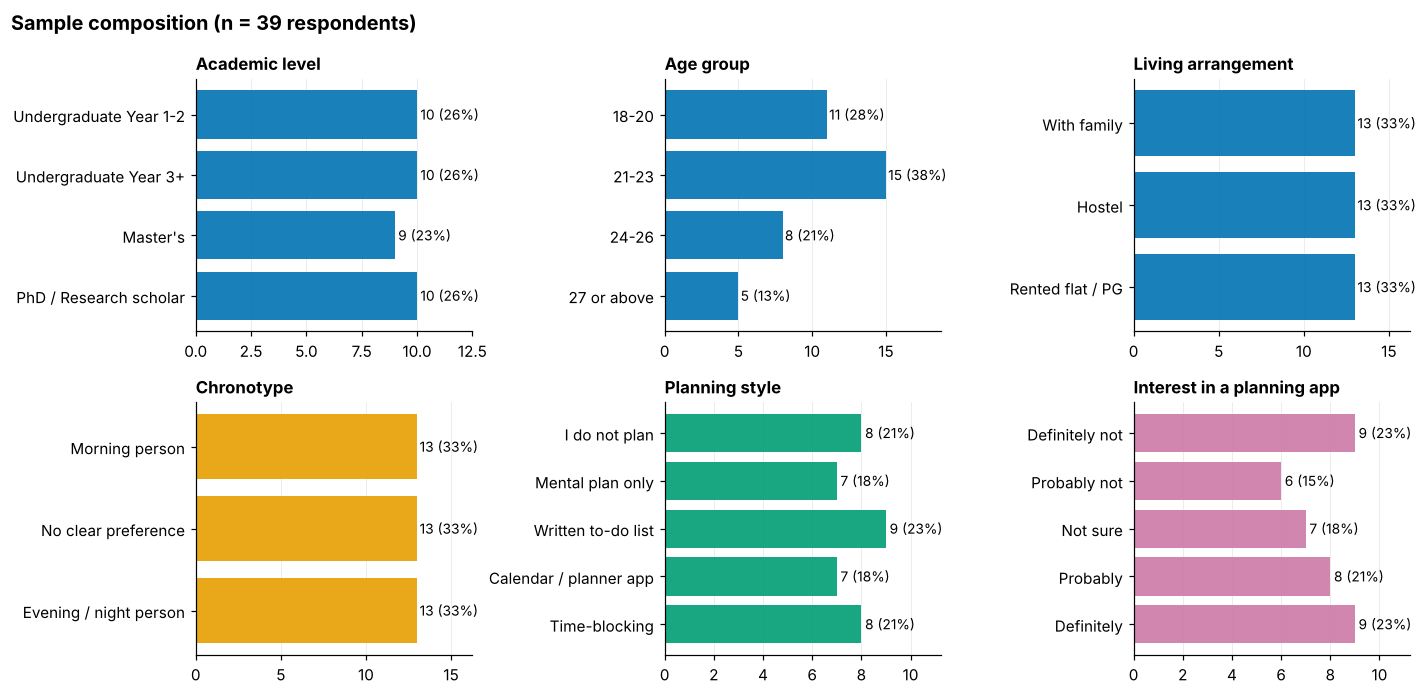

In [6]:
_ = P.fig_sample(r)

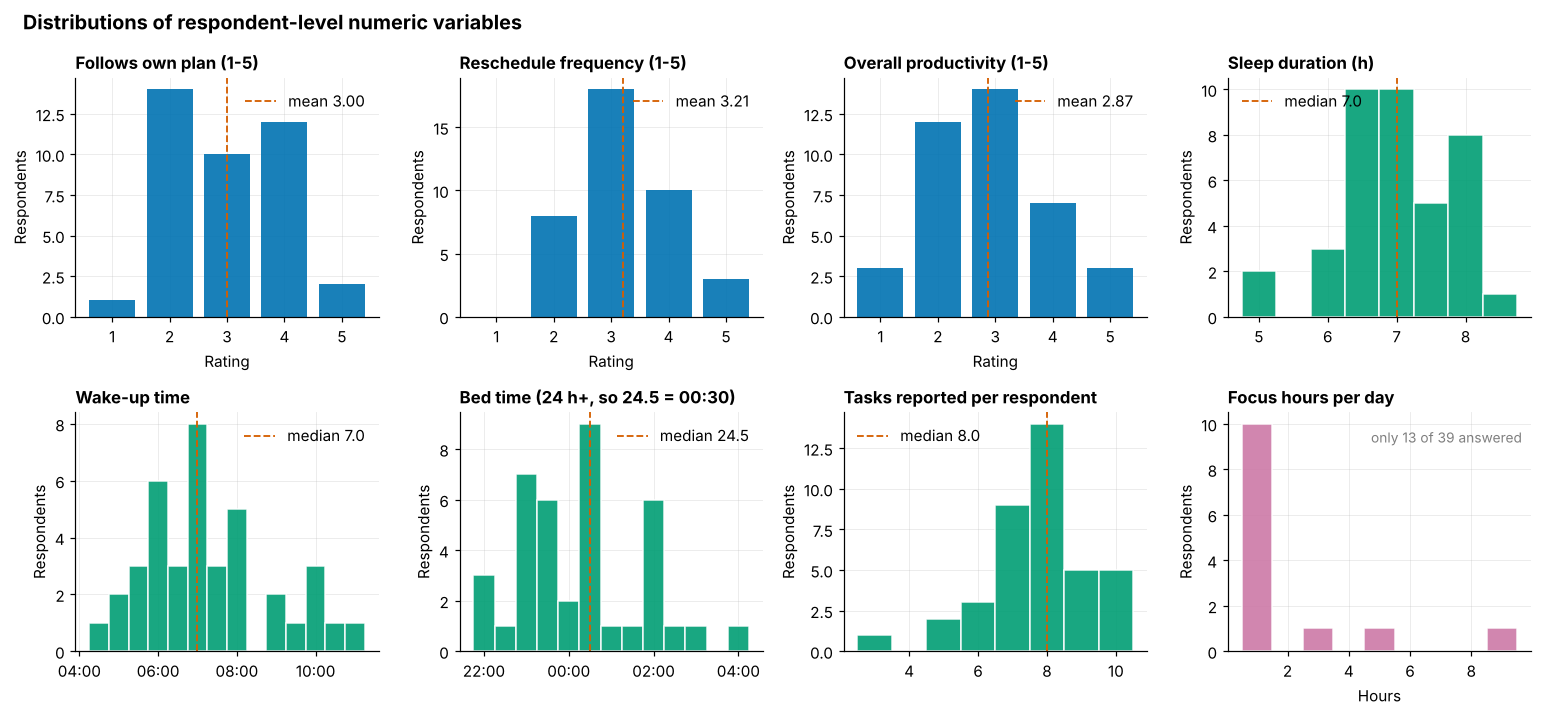

In [7]:
_ = P.fig_distributions(r)

**Reading the descriptives.**
* Respondents sleep **7.0 h** on average (SD 0.81, range 5-8.5), wake at about 07:17 and go to bed at about 00:17. They rate their overall productivity **2.9 / 5** and their adherence to their own plan **3.0 / 5**; rescheduling is fairly common (mean 3.2, nobody below 2).
* The sample is deliberately balanced (13/13/13 for chronotype and for living arrangement, ~10 per academic level), so these shares are design features, not findings.
* **Morning** is the most common self-reported peak time (46%), followed by night (23%).
* Ratings are not normally distributed and use few distinct values, which supports the non-parametric choices in Section 4.

### 2.1 Why plans go wrong, and what decides when tasks get done
Both questions were multiple-response. Each bar is the share of respondents ticking the option with a Wilson 95% CI.
**Cochran's Q** tests whether the options are equally common (a repeated-measures test for binary items).

Reasons plans fail : Q(7) = 22.09, p = .002
Timing decisions   : Q(6) = 24.96, p < .001


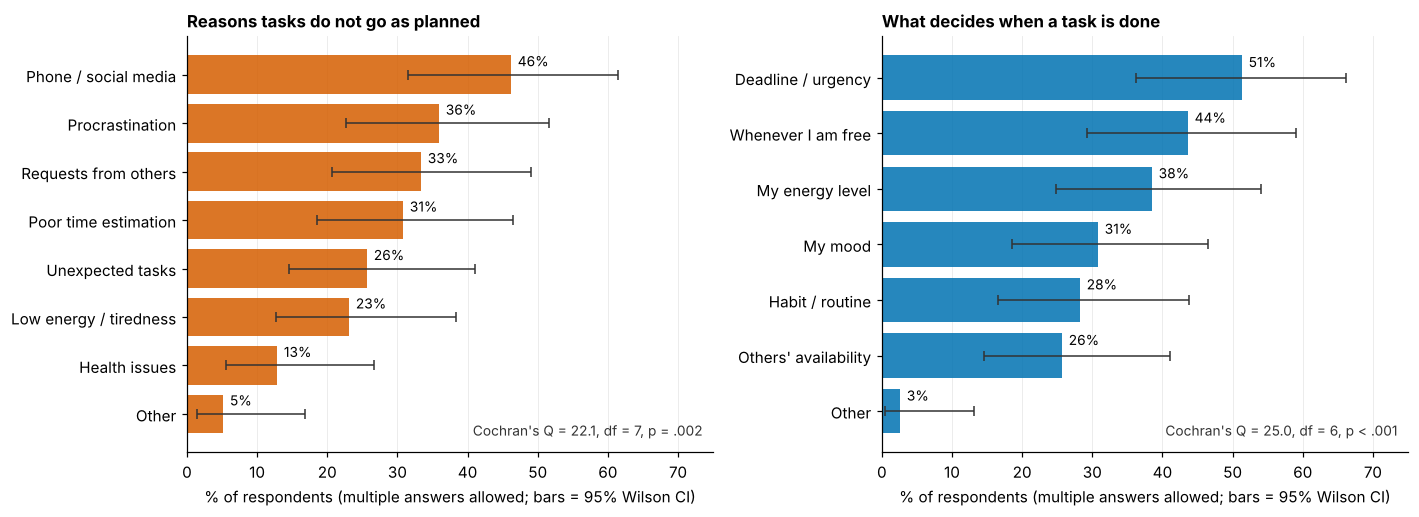

In [8]:
q_reasons = S.cochran_q(r[list(C.REASONS)].values)
q_decide = S.cochran_q(r[list(C.DECIDE)].values)
register("Multiple-response items", "Cochran's Q", "reasons plans fail", "option", 39, q_reasons["Q"], q_reasons["df"], q_reasons["p"], np.nan, "")
register("Multiple-response items", "Cochran's Q", "what decides timing", "option", 39, q_decide["Q"], q_decide["df"], q_decide["p"], np.nan, "")
print(f"Reasons plans fail : Q({q_reasons['df']}) = {q_reasons['Q']:.2f}, p {S.fmt_p(q_reasons['p'])}")
print(f"Timing decisions   : Q({q_decide['df']}) = {q_decide['Q']:.2f}, p {S.fmt_p(q_decide['p'])}")
_ = P.fig_reasons_decisions(r, q_reasons=q_reasons, q_decide=q_decide)

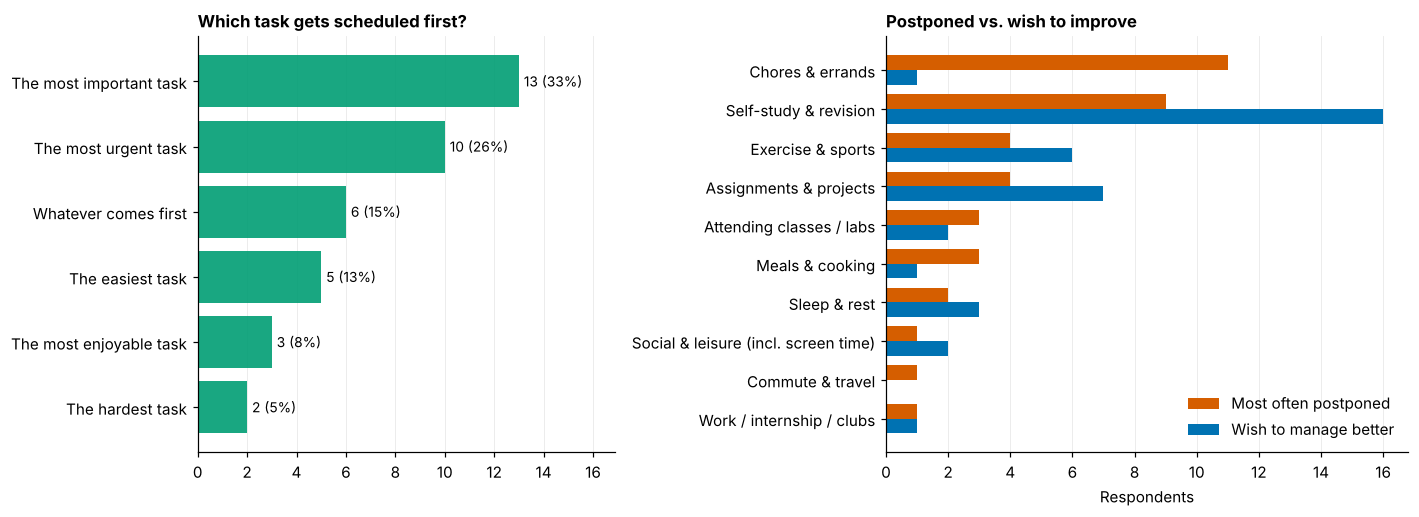

In [9]:
_ = P.fig_schedule_postpone(r)

**Reading the results.**
* The top reason plans fail is **phone / social media (46%)**, then procrastination (36%), requests from others (33%) and poor time estimation (31%). Health issues (13%) and "other" are rare. The options differ significantly in prevalence (Cochran's Q, p = .002), although the very low "other" and "health" options contribute to that; the 95% CIs of the top four overlap heavily, so their *ranking* is not reliable.
* Timing is mostly driven by **deadlines / urgency (51%)** and **whenever I am free (44%)**, then energy (38%); only 38% cite energy level, which fits the weak role of chronotype found below.
* Respondents most often postpone **chores (28%)** and **self-study (23%)**, yet 41% say **self-study** is what they most want to manage better.

## 3. Descriptive statistics: task reports (301 reports, 10 task types)
Respondents rated only tasks they actually do, so the number of reports differs by task type (sleep, leisure and meals are near-universal; work and exercise are not).

In [10]:
n_by_task = t["task_label"].value_counts().rename("n_reports")
task_tbl = t.groupby("task_label")[C.RATINGS + ["duration_min"]].mean().join(n_by_task)
task_tbl = task_tbl.sort_values("energy", ascending=False)
save_table(task_tbl.round(3), "descriptives_by_task")
save_table(S.describe_numeric(t, C.RATINGS + ["duration_min", "times_per_week", "n_blocks"]), "descriptives_task_overall")
task_tbl.round(2)

,importance,energy,productivity,satisfaction,completed,postponed,interruptions,duration_min,n_reports
task_label,,,,,,,,,
Exercise,3.47,4.05,3.58,3.58,3.21,3.47,2.16,64.74,19
Assignments,4.34,3.66,3.17,3.10,3.59,2.86,3.52,156.72,29
Self-study,4.15,3.64,3.27,3.36,3.15,3.18,3.58,171.82,33
Classes / labs,3.93,3.33,3.00,2.89,4.04,2.37,3.15,166.11,27
Work / clubs,3.70,3.30,3.40,3.30,4.20,2.05,2.80,195.00,20
Chores,2.93,3.07,2.90,2.87,3.30,2.97,2.73,83.50,30
Meals,3.32,2.58,2.79,3.29,3.84,2.42,2.42,60.00,38
Commute,2.41,2.33,2.04,2.37,3.89,2.30,2.74,72.78,27
Leisure,3.28,1.87,2.77,3.97,3.97,2.62,3.08,146.54,39


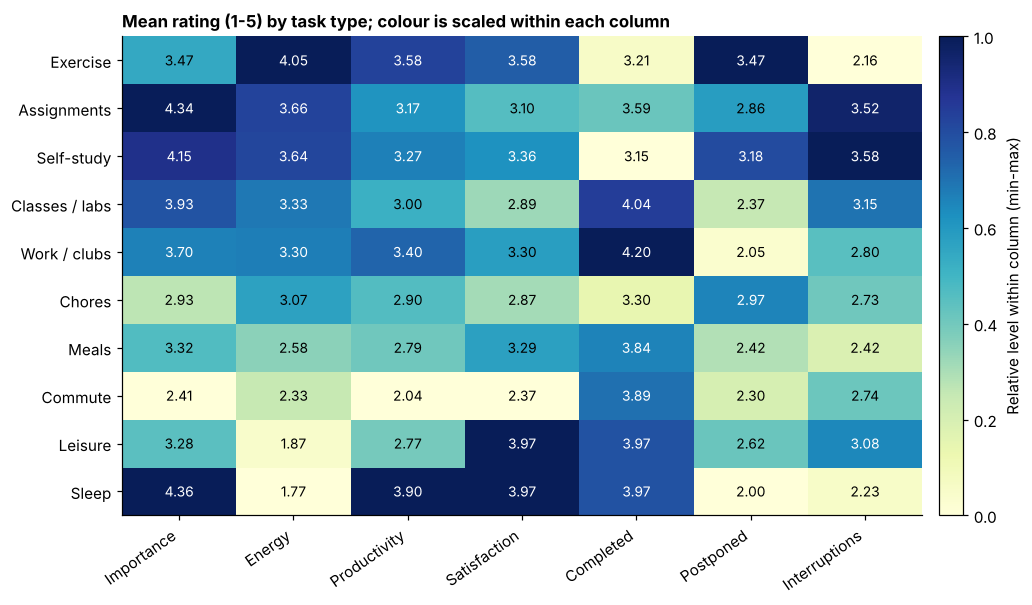

In [11]:
_ = P.fig_task_profile(t)

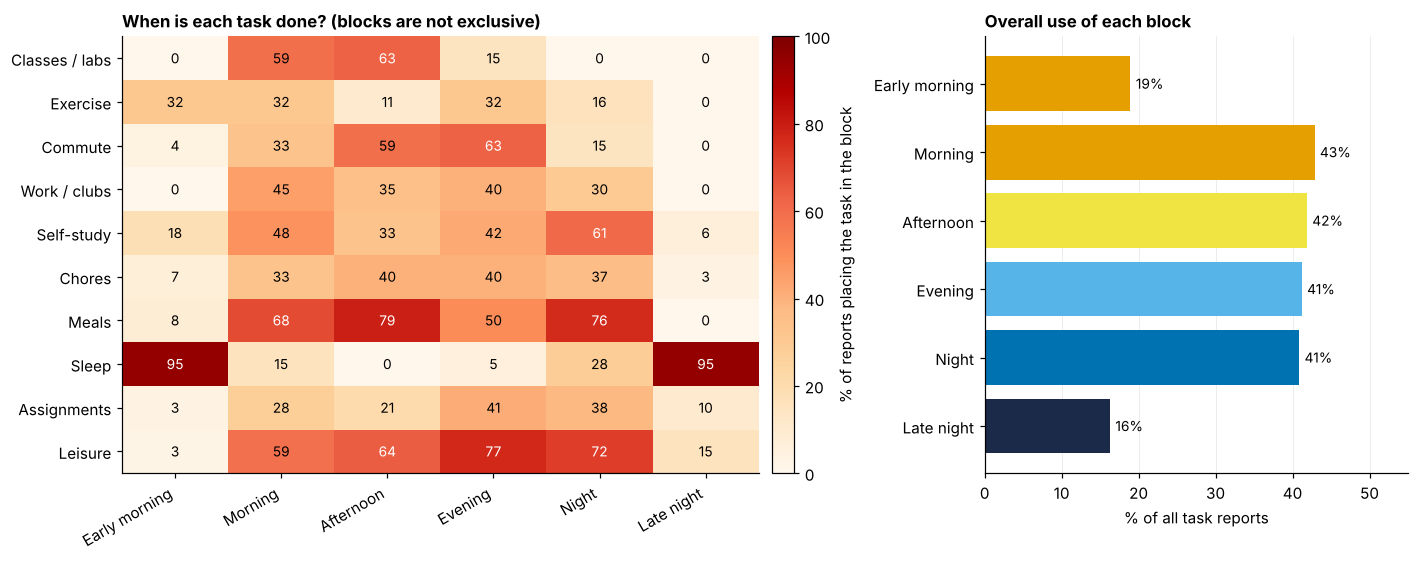

In [12]:
_ = P.fig_time_blocks(t)

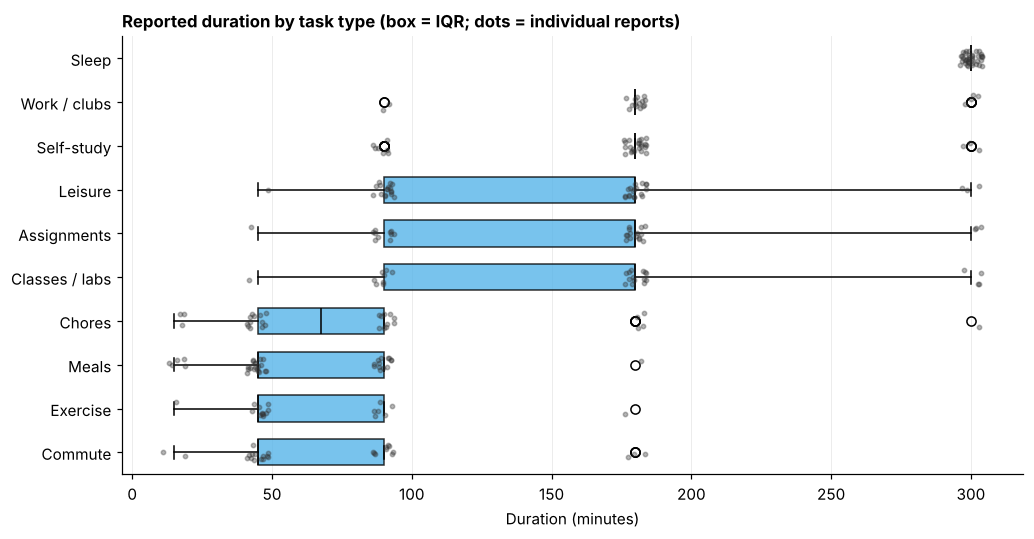

In [13]:
_ = P.fig_duration(t)

**Reading the results.**
* **Energy** varies most across tasks: highest for exercise (4.05), assignments (3.66) and self-study (3.64); lowest for sleep (1.77), leisure (1.87) and commuting (2.33).
* **Productivity** is highest for sleep (3.90) and exercise (3.58) and lowest for commuting (2.04). **Satisfaction** is highest for leisure and sleep (both 3.97) and lowest for commuting (2.37).
* **Interruptions** are heaviest during study (3.58) and assignments (3.52), which are also rated very important (4.2-4.3), and lightest during exercise (2.16).
* Timing is structured: classes cluster in the morning/afternoon, study peaks at night (61%), leisure in the evening/night, and sleep sits in the early-morning and late-night blocks (95% each). Blocks overlap, so shares do not sum to 100%.

## 4. Inferential analysis: respondent level (n = 39)

### 4.1 Checking assumptions (why non-parametric tests)

In [14]:
rows = []
for v in ["overall_productivity", "follow_plan", "reschedule_freq", "sleep_hours", "wake_h", "bed_h_night"]:
    W, p_sw = sps.shapiro(r[v])
    lev = sps.levene(*[g[v].values for _, g in r.groupby("chronotype", observed=True)], center="median")
    rows.append(dict(variable=v, shapiro_W=W, shapiro_p=p_sw, levene_p_by_chronotype=lev.pvalue, distinct_values=r[v].nunique()))
assump = pd.DataFrame(rows).set_index("variable")
save_table(assump, "assumption_checks")
assump

,shapiro_W,shapiro_p,levene_p_by_chronotype,distinct_values
variable,,,,
overall_productivity,0.912,4.859e-03,0.387,5
follow_plan,0.876,4.925e-04,0.607,5
reschedule_freq,0.866,2.699e-04,0.180,4
sleep_hours,0.931,1.941e-02,0.413,7
wake_h,0.947,6.654e-02,0.093,13
bed_h_night,0.947,6.566e-02,0.912,12


Shapiro-Wilk rejects normality for four of six variables (productivity, plan adherence, rescheduling, sleep hours; all p < .05), the rating scales have only 4-7 distinct values, and group sizes are 7-15. Levene tests do not reject equal variances, but with such small ordinal samples rank-based tests are the safer, primary choice.

### 4.2 Group differences (Kruskal-Wallis, Holm-corrected across the family)
**Family of 13 tests:** chronotype → 6 outcomes; planning style → 4 outcomes; academic level, living arrangement and age group → overall productivity.
Wake time and bed time are included as *validity checks* of the chronotype question (a morning person should wake earlier).
Effect size is epsilon-squared (0 = none, ≈0.01 small, ≈0.06 medium, ≈0.14 large).

In [15]:
tests = [("overall_productivity", "chronotype"), ("sleep_hours", "chronotype"), ("wake_h", "chronotype"),
         ("bed_h_night", "chronotype"), ("follow_plan", "chronotype"), ("reschedule_freq", "chronotype"),
         ("follow_plan", "plan_style"), ("overall_productivity", "plan_style"), ("reschedule_freq", "plan_style"),
         ("app_score", "plan_style"),
         ("overall_productivity", "level"), ("overall_productivity", "living"), ("overall_productivity", "age_group")]
kw = pd.DataFrame([S.kruskal_effect(r, o, f) for o, f in tests])
kw["p_holm"] = S.holm(kw["p"].values)
kw["significant"] = kw["p_holm"] < C.ALPHA
for _, row in kw.iterrows():
    register("Respondent group differences (Holm, 13 tests)", "Kruskal-Wallis", row.outcome, row.factor, row.n, row.statistic, row.df, row.p, row.effect_size, "epsilon^2")
save_table(kw.set_index(["factor", "outcome"]), "inferential_group_differences")
show_p(kw[["factor", "outcome", "n", "statistic", "df", "p", "p_holm", "effect_size", "significant"]].round(3), ["p", "p_holm"])

,factor,outcome,n,statistic,df,p,p_holm,effect_size,significant
0,chronotype,overall_productivity,39,0.469,2,.791,1.000,0.000,False
1,chronotype,sleep_hours,39,0.643,2,.725,1.000,0.000,False
2,chronotype,wake_h,39,23.122,2,< .001,< .001,0.587,True
3,chronotype,bed_h_night,39,27.574,2,< .001,< .001,0.710,True
4,chronotype,follow_plan,39,0.605,2,.739,1.000,0.000,False
5,chronotype,reschedule_freq,39,2.647,2,.266,1.000,0.018,False
6,plan_style,follow_plan,39,20.443,4,< .001,.004,0.484,True
7,plan_style,overall_productivity,39,9.507,4,.050,.496,0.162,False
8,plan_style,reschedule_freq,39,1.097,4,.895,1.000,0.000,False
9,plan_style,app_score,39,4.673,4,.323,1.000,0.020,False


In [16]:
# Post-hoc pairwise Mann-Whitney (Holm) for every comparison that survived correction
for _, row in kw[kw["significant"]].iterrows():
    ph = S.pairwise_mwu_holm(r, row.outcome, row.factor)
    print(f"\n== {row.outcome} by {row.factor} ==")
    print(show_p(ph[["group_a", "group_b", "n1", "n2", "U", "p", "p_holm", "rank_biserial"]].round(3), ["p", "p_holm"]).to_string(index=False))
    save_table(ph, f"posthoc_{row.outcome}_by_{row.factor}")


== wake_h by chronotype ==
            group_a                group_b  n1  n2    U      p p_holm  rank_biserial
     Morning person    No clear preference  13  13 41.5   .027   .027         -0.509
     Morning person Evening / night person  13  13  4.0 < .001 < .001         -0.953
No clear preference Evening / night person  13  13 15.0 < .001   .001         -0.822

== bed_h_night by chronotype ==
            group_a                group_b  n1  n2    U      p p_holm  rank_biserial
     Morning person    No clear preference  13  13 32.0   .006   .006         -0.621
     Morning person Evening / night person  13  13  1.0 < .001 < .001         -0.988
No clear preference Evening / night person  13  13  6.0 < .001 < .001         -0.929

== follow_plan by plan_style ==
               group_a                group_b  n1  n2    U     p p_holm  rank_biserial
         I do not plan       Mental plan only   8   7 23.5  .580  1.000         -0.161
         I do not plan     Written to-do list   8   

In [17]:
kw_by = {f: {row.outcome: row.to_dict() for _, row in kw[kw.factor == f].iterrows()} for f in ["chronotype", "plan_style"]}
r.groupby("chronotype", observed=True)[["overall_productivity", "sleep_hours", "wake_h", "bed_h_night", "follow_plan"]].agg(["mean", "std"]).round(2)

overall_productivity       sleep_hours       wake_h       bed_h_night       follow_plan      
                                       mean   std        mean   std   mean   std        mean   std        mean   std
chronotype                                                                                                          
Morning person                         2.77  1.01        7.00  0.79   6.00  0.87       23.00  0.74        2.85  0.90
No clear preference                    2.92  1.26        6.92  0.70   6.85  0.83       23.92  0.64        3.08  1.12
Evening / night person                 2.92  0.95        7.08  0.98   9.00  1.31       25.92  0.95        3.08  1.04

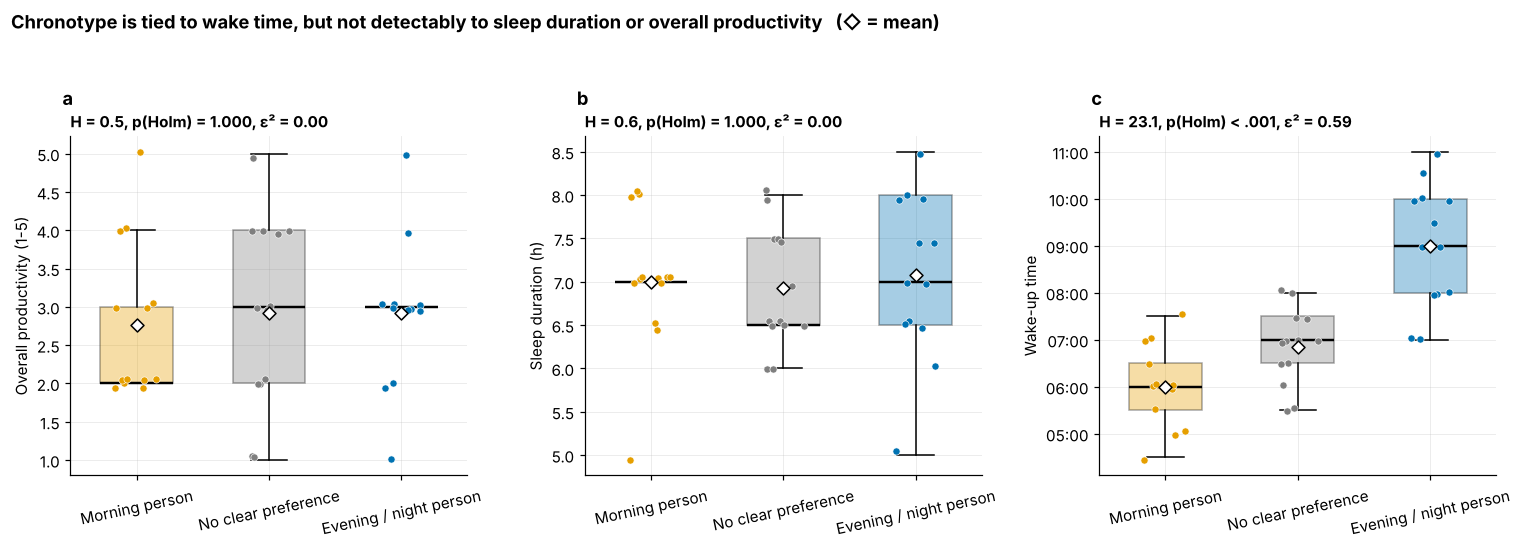

In [18]:
_ = P.fig_chronotype(r, kw_by['chronotype'])

In [19]:
r.groupby("plan_style", observed=True)[["follow_plan", "overall_productivity", "reschedule_freq", "app_score"]].agg(["mean", "std"]).round(2)

follow_plan       overall_productivity       reschedule_freq       app_score      
                              mean   std                 mean   std            mean   std      mean   std
plan_style                                                                                               
I do not plan                 2.12  0.64                 2.88  0.64            3.12  0.64      2.88  1.81
Mental plan only              2.43  0.79                 2.71  1.25            3.14  0.69      3.86  1.68
Written to-do list            2.78  0.83                 2.11  0.93            3.33  1.00      3.44  1.01
Calendar / planner app        3.86  0.69                 3.71  1.25            3.00  1.15      2.43  1.81
Time-blocking                 3.88  0.64                 3.12  0.64            3.38  0.92      2.62  1.06

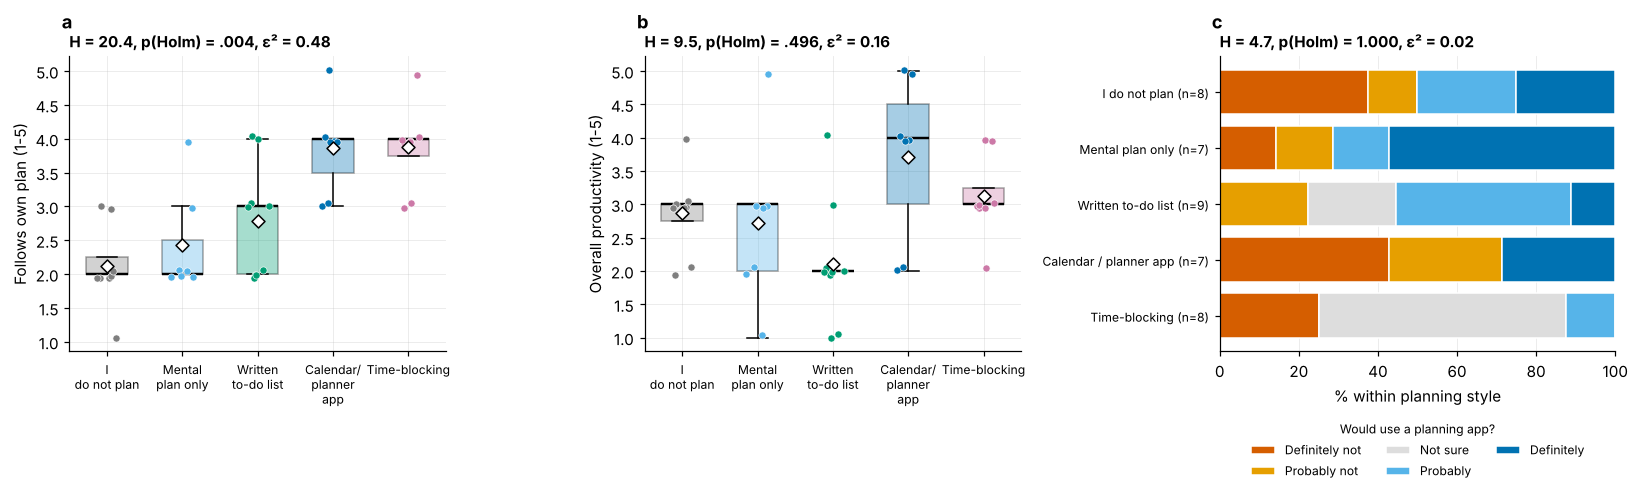

In [20]:
_ = P.fig_plan_style(r, kw_by['plan_style'])

**Reading the results.**
* **Chronotype validity check passes:** wake time differs strongly by chronotype (median 06:00 morning / 07:00 no preference / 09:00 evening; ε² = 0.59) and so does bed time (ε² = 0.71); all pairwise comparisons are significant after Holm correction.
* **Chronotype does *not* detectably relate to overall productivity, sleep duration, plan adherence or rescheduling** (all adjusted p = 1.00, ε² ≤ 0.02). Evening types shift their day later but sleep as long (about 7 h) and rate their productivity the same. With 13 per group, small differences could still be missed.
* **Planning style strongly differs in plan adherence** (H = 20.4, Holm p = .004, ε² = 0.48). Users of a calendar/planner app (3.86) and time-blockers (3.88) follow their plans far more than people who do not plan (2.12); both contrasts survive Holm correction (p = .020 and .013). Intermediate styles are not clearly separable at this sample size.
* Planning style and overall productivity show a hint of a difference (raw p = .050, ε² = 0.16), but it does **not** survive correction (Holm p = .50) and is not a finding. Descriptively, calendar-app users rate productivity highest (3.71) and written to-do-list users lowest (2.11), which could be explored in a larger sample.
* Academic level, living arrangement and age group show no detectable differences in productivity.

### 4.3 Associations between respondent-level variables (Spearman)
All 28 pairwise correlations among eight variables, each with a bootstrap 95% CI; stars use **Holm-adjusted** p-values.
`app_score` codes interest in a planning app from 1 (definitely not) to 5 (definitely). Wake and bed times are on a 24 h+ scale.

In [21]:
cvars = ["follow_plan", "reschedule_freq", "overall_productivity", "sleep_hours", "wake_h", "bed_h_night", "n_tasks_done", "app_score"]
clabels = ["Follows plan", "Reschedule freq.", "Productivity", "Sleep hours", "Wake time", "Bed time", "# tasks reported", "App interest"]
pairs, res = [], {}
for i, a in enumerate(cvars):
    for b in cvars[i + 1:]:
        s = S.spearman_boot(r[a], r[b], n_boot=2000, seed=C.SEED)
        res[(a, b)] = res[(b, a)] = s
        pairs.append(dict(var_a=a, var_b=b, **s))
corr = pd.DataFrame(pairs)
corr["p_holm"] = S.holm(corr["p"].values)
for _, row in corr.iterrows():
    register("Respondent correlations (Holm, 28 tests)", "Spearman", row.var_a, row.var_b, row.n, row.rho, np.nan, row.p, row.rho, "rho")
save_table(corr.set_index(["var_a", "var_b"]), "inferential_respondent_correlations")

k = len(cvars); rho = np.eye(k); stars = [[""] * k for _ in range(k)]
for i, a in enumerate(cvars):
    for j, b in enumerate(cvars):
        if i != j:
            rho[i, j] = res[(a, b)]["rho"]
            ph = corr[((corr.var_a == a) & (corr.var_b == b)) | ((corr.var_a == b) & (corr.var_b == a))]["p_holm"].iloc[0]
            stars[i][j] = P._stars(ph)
show_p(corr.sort_values("p").head(8)[["var_a", "var_b", "rho", "ci_low", "ci_high", "p", "p_holm"]].round(3), ["p", "p_holm"])

,var_a,var_b,rho,ci_low,ci_high,p,p_holm
22,wake_h,bed_h_night,0.845,0.715,0.926,< .001,< .001
1,follow_plan,overall_productivity,0.582,0.317,0.795,< .001,.003
18,sleep_hours,wake_h,0.410,0.119,0.649,.010,.250
24,wake_h,app_score,0.304,-0.022,0.584,.060,1.000
26,bed_h_night,app_score,0.301,-0.028,0.593,.063,1.000
17,overall_productivity,app_score,-0.296,-0.562,0.025,.067,1.000
3,follow_plan,wake_h,0.254,-0.069,0.550,.119,1.000
14,overall_productivity,wake_h,0.238,-0.055,0.523,.144,1.000


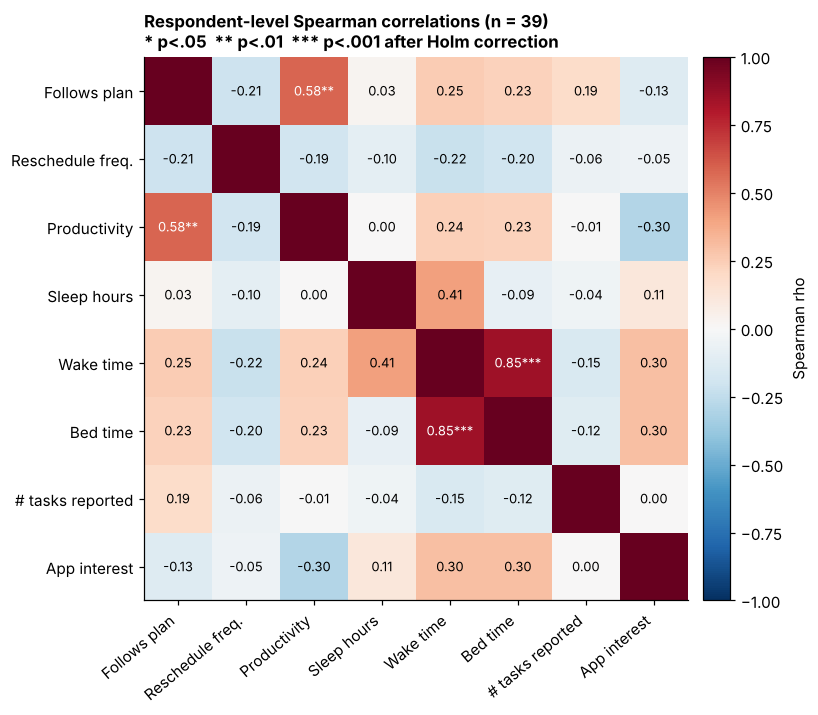

In [22]:
_ = P.fig_corr_respondent(rho, stars, clabels)

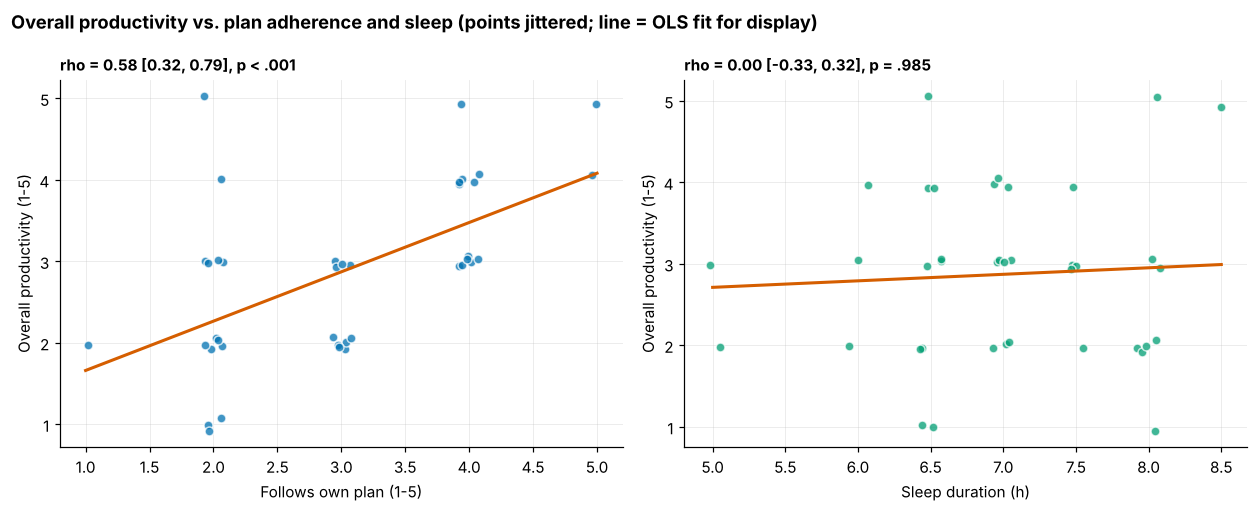

In [23]:
_ = P.fig_scatter_productivity(r, {"follow_plan": res[("follow_plan", "overall_productivity")],
                                   "sleep_hours": res[("sleep_hours", "overall_productivity")]})

**Reading the results.**
* Besides the expected wake-time/bed-time link (ρ = 0.85), the only association that survives Holm correction is **plan adherence ↔ overall productivity: ρ = 0.58, 95% CI [0.32, 0.80], Holm p = .003.** People who stick to their plans feel more productive. This is correlational (productive people may also find it easier to follow plans).
* **Sleep duration is unrelated to overall productivity at the respondent level** (ρ ≈ 0.00). Keep this in mind when reading the task-level model in 5.3, where sleep hours has a positive coefficient.
* Interest in a planning app is only weakly related to the other variables: the largest coefficients (|ρ| ≈ 0.30, with wake time, bed time and productivity) are all non-significant after Holm correction.

### 4.4 Chronotype and self-reported peak time (chi-square with permutation p-value)
Peak time is collapsed to three bands (Morning; Afternoon/evening; Night/late night). The two respondents answering "No difference" are excluded from this test.
With 37 respondents and a 3 × 3 table many expected counts are < 5, so the p-value comes from 10,000 label permutations rather than the chi-square approximation.

peak_band               Morning  Afternoon / evening  Night / late night
chronotype                                                              
Morning person               13                    0                   0
No clear preference           5                    6                   0
Evening / night person        0                    1                  12 

{'chi2': 46.2531, 'dof': 4.0, 'p_asymptotic': 0.0, 'p_perm': 0.0022, 'cramers_v_bc': 0.7765, 'n': 37.0, 'min_expected': 2.0811, 'pct_cells_expected_lt5': 66.6667}


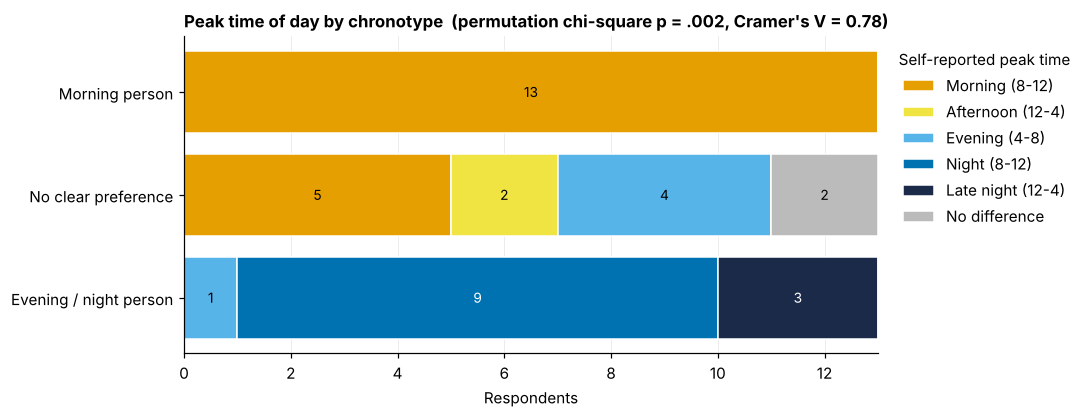

In [24]:
band = {"Morning (8-12)": "Morning", "Afternoon (12-4)": "Afternoon / evening", "Evening (4-8)": "Afternoon / evening",
        "Night (8-12)": "Night / late night", "Late night (12-4)": "Night / late night"}
rp = r[r["peak_time"].astype(str).isin(band)].copy()
rp["peak_band"] = pd.Categorical(rp["peak_time"].astype(str).map(band),
                                 categories=["Morning", "Afternoon / evening", "Night / late night"], ordered=True)
tab = pd.crosstab(rp["chronotype"], rp["peak_band"])
chi = S.perm_chi2(rp["chronotype"].astype(str), rp["peak_band"].astype(str), n_perm=10000, seed=C.SEED)
register("Categorical association", "Chi-square (permutation p)", "peak band", "chronotype", chi["n"], chi["chi2"], chi["dof"], chi["p_perm"], chi["cramers_v_bc"], "Cramer's V (bias-corrected)")
print(tab, "\n")
print({k: round(float(v), 4) for k, v in chi.items()})
_ = P.fig_peak_by_chronotype(r, chi)

**Reading the results.** Self-reported chronotype and peak time agree very strongly (permutation p = .002, bias-corrected Cramér's V = 0.78): all 13 morning types peak in the morning, and 12 of 13 evening types peak at night or late night. "No clear preference" respondents split between morning and afternoon/evening peaks. This is a second confirmation that the chronotype variable is meaningful.

### 4.5 Sensitivity analysis: excluding the four flagged respondents
The cleaning step flagged two sleep-duration outliers and two straight-liners. If conclusions depend on them they are fragile.

In [25]:
r2 = r[~r["flagged"]]
kw2 = pd.DataFrame([S.kruskal_effect(r2, o, f) for o, f in tests])
kw2["p_holm"] = S.holm(kw2["p"].values)
sens = kw[["factor", "outcome", "p", "p_holm", "effect_size"]].merge(
    kw2[["factor", "outcome", "p", "p_holm", "effect_size"]], on=["factor", "outcome"], suffixes=("_all", "_excl"))
sens["same_decision"] = (sens["p_holm_all"] < .05) == (sens["p_holm_excl"] < .05)
# key correlation
rho_all = S.spearman_boot(r["follow_plan"], r["overall_productivity"], 1000, C.SEED)
rho_ex = S.spearman_boot(r2["follow_plan"], r2["overall_productivity"], 1000, C.SEED)
save_table(sens.set_index(["factor", "outcome"]), "sensitivity_excluding_flagged")
print(f"n excluded = {int(r['flagged'].sum())}; all {len(sens)} Holm decisions unchanged: {bool(sens['same_decision'].all())}")
print(f"follow_plan ~ productivity: rho = {rho_all['rho']:.2f} (all) vs {rho_ex['rho']:.2f} (excluding flagged, n = {rho_ex['n']})")
show_p(sens.round(3), ["p_all", "p_holm_all", "p_excl", "p_holm_excl"])

n excluded = 4; all 13 Holm decisions unchanged: True
follow_plan ~ productivity: rho = 0.58 (all) vs 0.57 (excluding flagged, n = 35)


,factor,outcome,p_all,p_holm_all,effect_size_all,p_excl,p_holm_excl,effect_size_excl,same_decision
0,chronotype,overall_productivity,.791,1.000,0.000,.939,1.000,0.000,True
1,chronotype,sleep_hours,.725,1.000,0.000,.330,1.000,0.007,True
2,chronotype,wake_h,< .001,< .001,0.587,< .001,< .001,0.593,True
3,chronotype,bed_h_night,< .001,< .001,0.710,< .001,< .001,0.712,True
4,chronotype,follow_plan,.739,1.000,0.000,.887,1.000,0.000,True
5,chronotype,reschedule_freq,.266,1.000,0.018,.356,1.000,0.002,True
6,plan_style,follow_plan,< .001,.004,0.484,< .001,.005,0.541,True
7,plan_style,overall_productivity,.050,.496,0.162,.098,.782,0.128,True
8,plan_style,reschedule_freq,.895,1.000,0.000,.460,1.000,0.000,True
9,plan_style,app_score,.323,1.000,0.020,.373,1.000,0.008,True


**Reading the results.** Dropping the four flagged respondents changes no Holm-adjusted decision among the 13 respondent-level tests, and the key correlation barely moves (ρ = 0.58 → 0.57). The conclusions in 4.2-4.4 are not driven by the outlier or straight-lining cases.

## 5. Inferential analysis: task level (301 reports from 39 respondents)
Because each respondent contributes up to ten reports, rows from the same person are correlated. Treating them as independent would overstate precision.
Everything below therefore uses **respondent-clustered** inference (cluster-robust CR1 standard errors with *G − 1* = 38 df, or a bootstrap that resamples whole respondents).

### 5.1 Do task types differ?
Kruskal-Wallis ignores clustering, so it is shown only for effect size. The **p-value used is from a cluster-robust joint Wald test** that all task-type coefficients are equal (F-test, 9 and 38 df), Holm-corrected over six outcomes.

In [26]:
rows = []
for o in ["energy", "productivity", "satisfaction", "completed", "postponed", "interruptions"]:
    kwr = S.kruskal_effect(t, o, "task")
    X = S.design_matrix(t, categorical=["task"])
    fit = S.cluster_ols(t[o], X, t["row_id"])
    w = S.wald_cluster(fit, [c for c in fit["names"] if c.startswith("task_")])
    rows.append(dict(outcome=o, epsilon2=kwr["effect_size"], R2_task_only=fit["r2"], F=w["F"], df1=w["df1"], df2=w["df2"], p_cluster=w["p"]))
tt = pd.DataFrame(rows)
tt["p_holm"] = S.holm(tt["p_cluster"].values)
for _, row in tt.iterrows():
    register("Task-type differences (Holm, 6 tests)", "Cluster-robust Wald F", row.outcome, "task type", 301, row.F, f"{int(row.df1)},{int(row.df2)}", row.p_cluster, row.epsilon2, "epsilon^2 (KW)")
save_table(tt.set_index("outcome"), "inferential_task_type_differences")
show_p(tt.round(3), ["p_cluster", "p_holm"])

,outcome,epsilon2,R2_task_only,F,df1,df2,p_cluster,p_holm
0,energy,0.440,0.427,19.361,9,38,< .001,< .001
1,productivity,0.187,0.212,17.672,9,38,< .001,< .001
2,satisfaction,0.188,0.214,12.753,9,38,< .001,< .001
3,completed,0.093,0.109,7.019,9,38,< .001,< .001
4,postponed,0.130,0.148,6.207,9,38,< .001,< .001
5,interruptions,0.167,0.187,8.123,9,38,< .001,< .001


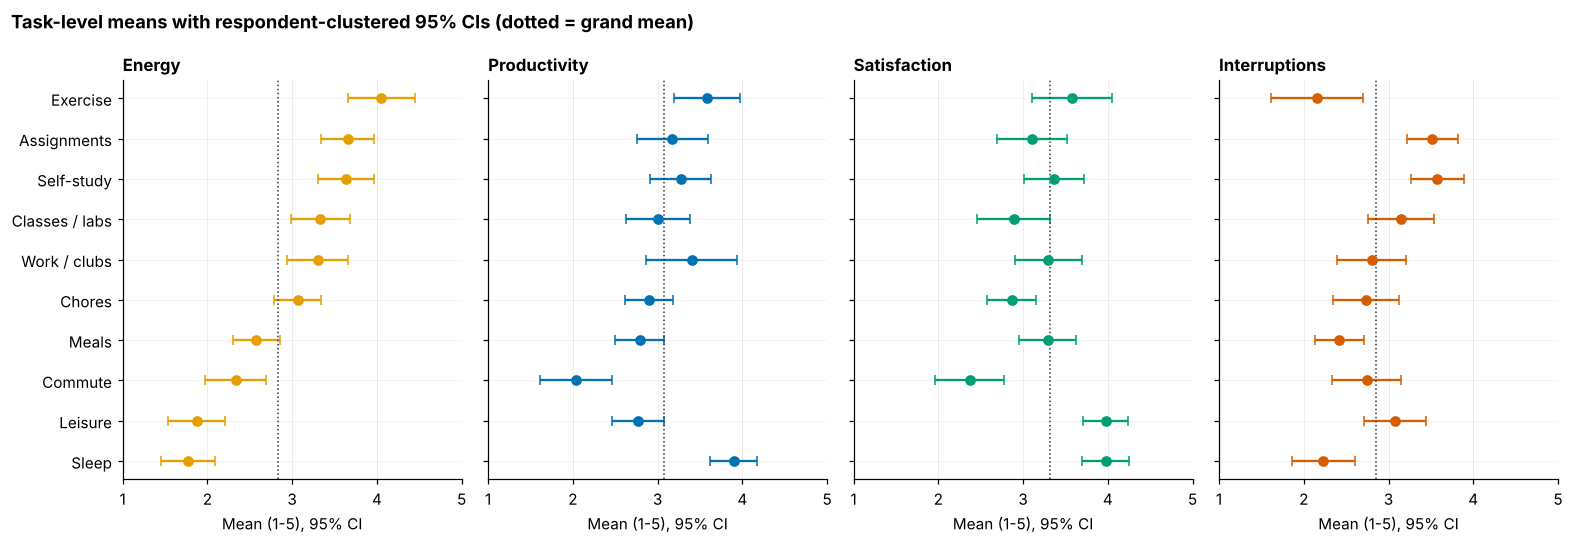

In [27]:
_ = P.fig_task_means(t)

**Reading the results.** Task type matters for every outcome (cluster-robust Wald, all Holm p < .001). Using the Kruskal-Wallis ε² as an effect size, it matters most for **energy (ε² = 0.44, large)**, moderately for productivity (0.19), satisfaction (0.19) and interruptions (0.17), and least for completion (0.09). Energy is the rating that is most "about the task" (sleep and leisure low, exercise and study high), while productivity and satisfaction are shaped by other factors as well (next sections).

### 5.2 Correlations among task ratings (cluster bootstrap)
Respondents are resampled with replacement (1,000 times) and the whole correlation matrix is recomputed; a coefficient is starred when its 95% interval excludes zero.
These intervals are *not* multiplicity-adjusted (21 coefficients), so treat borderline intervals cautiously.

,var_a,var_b,rho,ci_low,ci_high,ci_excludes_0
11,productivity,satisfaction,0.578,0.479,0.676,True
18,completed,postponed,-0.566,-0.713,-0.330,True
1,importance,productivity,0.346,0.231,0.464,True
2,importance,satisfaction,0.300,0.150,0.445,True
15,satisfaction,completed,0.235,0.061,0.399,True
12,productivity,completed,0.226,0.061,0.380,True
9,energy,postponed,0.225,0.081,0.400,True
20,postponed,interruptions,0.225,0.054,0.421,True


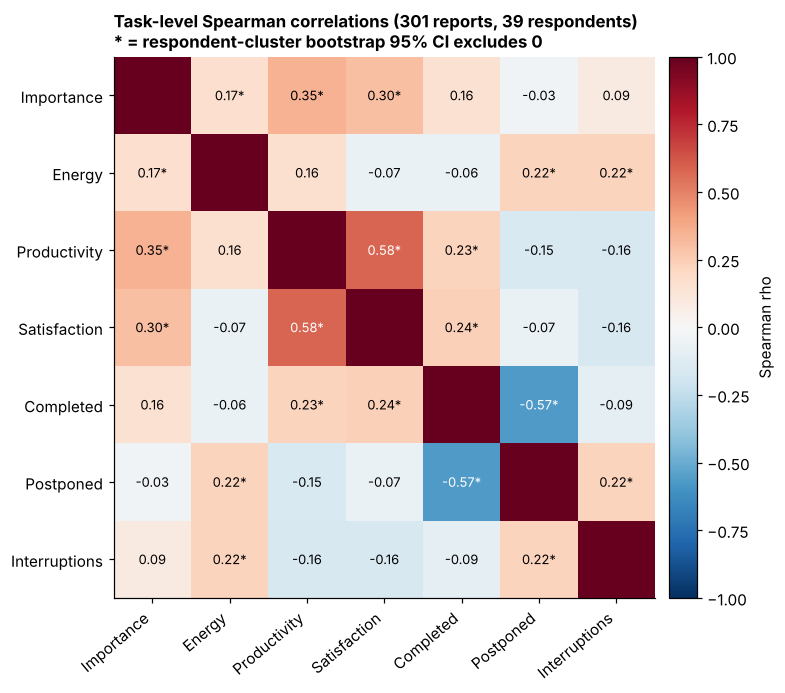

In [28]:
tv = ["importance", "energy", "productivity", "satisfaction", "completed", "postponed", "interruptions"]
k = len(tv); R = np.eye(k); LO = np.zeros((k, k)); HI = np.zeros((k, k)); rows = []
for i, a in enumerate(tv):
    for j in range(i + 1, k):
        b = tv[j]
        s = S.spearman_boot(t[a], t[b], n_boot=1000, seed=C.SEED, clusters=t["row_id"])
        R[i, j] = R[j, i] = s["rho"]; LO[i, j] = LO[j, i] = s["ci_low"]; HI[i, j] = HI[j, i] = s["ci_high"]
        rows.append(dict(var_a=a, var_b=b, rho=s["rho"], ci_low=s["ci_low"], ci_high=s["ci_high"]))
tcorr = pd.DataFrame(rows); tcorr["ci_excludes_0"] = (tcorr.ci_low > 0) | (tcorr.ci_high < 0)
save_table(tcorr.set_index(["var_a", "var_b"]), "inferential_task_correlations")
_ = P.fig_corr_task(R, LO, HI, [v.capitalize() for v in tv])
tcorr.reindex(tcorr["rho"].abs().sort_values(ascending=False).index).head(8).round(3)

**Reading the results.**
* **Productivity ↔ satisfaction** is the strongest link (ρ = 0.58, 95% CI [0.48, 0.68]).
* Tasks rated more **completed** are less **postponed** (ρ = -0.57, [-0.71, -0.33]).
* More **important** tasks are rated more productive (ρ = 0.35) and more satisfying (ρ = 0.30).
* Energy is mildly *positively* related to postponement (ρ = 0.23): tasks that demand energy (exercise, assignments, study) are the ones put off.

### 5.3 Cluster-robust regression: what explains a task's productivity and satisfaction?
OLS on the 1-5 ratings (an approximation for ordinal outcomes, chosen for interpretability), with respondent-clustered SEs.
Continuous predictors are **z-scored**, so each coefficient is the rating change per one standard deviation. Task type enters as dummies (reference = Assignments).
`energy`, `importance`, `interruptions` and `postponed` are the *same person's* ratings of the same task, so this is an **associational** model (reverse causation is plausible, e.g. productive tasks feel energising).

In [29]:
preds = ["energy", "importance", "interruptions", "postponed", "deadline", "flexibility", "log_duration", "follow_plan", "sleep_hours"]
pretty = {"energy": "Energy during task", "importance": "Importance", "interruptions": "Interruptions", "postponed": "Postponed",
          "deadline": "Deadline pressure (0-2)", "flexibility": "Flexibility (0-2)", "log_duration": "log(duration)",
          "follow_plan": "Follows own plan (resp.)", "sleep_hours": "Sleep hours (resp.)"}
X = S.design_matrix(t, numeric=preds, categorical=["task"])
vif = pd.Series(np.diag(np.linalg.inv(np.corrcoef(X[preds].values.T))), index=preds, name="VIF")
print("Max variance-inflation factor among numeric predictors: %.2f (no multicollinearity concern if < 5)" % vif.max())

fits, tables = {}, {}
for y in ["productivity", "satisfaction"]:
    f = S.cluster_ols(t[y], X, t["row_id"])
    w = S.wald_cluster(f, [c for c in f["names"] if c.startswith("task_")])
    tables[y] = f["table"]
    save_table(f["table"].round(4), f"model_{y}_cluster_ols")
    print(f"{y:13s} R2 = {f['r2']:.3f}  adj.R2 = {f['adj_r2']:.3f}  n = {f['n']}  clusters = {f['G']}  |  task-type joint Wald F({w['df1']},{w['df2']}) = {w['F']:.2f}, p = {w['p']:.4f}")
    register("Task-level regression", "Cluster-robust OLS", y, "all predictors (R2)", f["n"], f["r2"], f["k"], np.nan, f["r2"], "R^2")
    for name in preds:
        row = f["table"].loc[name]
        register(f"Regression: {y}", "Cluster-robust t", y, name, f["n"], row["t"], f["G"] - 1, row["p"], row["coef"], "z-scored beta")
    sub = f["table"].loc[preds].rename(index=pretty)
    fits[f"Outcome: {y}"] = (sub, f["r2"], f["n"], f["G"])
pd.concat({y: show_p(tables[y].loc[preds].rename(index=pretty)[["coef", "ci_low", "ci_high", "p"]].round(3), ["p"]) for y in tables}, axis=1)

Max variance-inflation factor among numeric predictors: 1.32 (no multicollinearity concern if < 5)
productivity  R2 = 0.423  adj.R2 = 0.386  n = 301  clusters = 39  |  task-type joint Wald F(9,38) = 5.15, p = 0.0001
satisfaction  R2 = 0.339  adj.R2 = 0.297  n = 301  clusters = 39  |  task-type joint Wald F(9,38) = 9.96, p = 0.0000


productivity                      satisfaction                     
                                 coef ci_low ci_high     p         coef ci_low ci_high     p
Energy during task              0.193  0.012   0.374  .038        0.114 -0.082   0.310  .247
Importance                      0.169 -0.018   0.355  .075        0.288  0.081   0.495  .008
Interruptions                  -0.155 -0.291  -0.019  .026       -0.172 -0.335  -0.009  .039
Postponed                      -0.055 -0.219   0.109  .502        0.026 -0.145   0.197  .758
Deadline pressure (0-2)        -0.063 -0.215   0.089  .409       -0.088 -0.231   0.054  .216
Flexibility (0-2)              -0.112 -0.215  -0.009  .034       -0.032 -0.152   0.088  .591
log(duration)                   0.126 -0.000   0.253  .051        0.084 -0.114   0.281  .396
Follows own plan (resp.)        0.237  0.087   0.387  .003        0.146 -0.012   0.304  .069
Sleep hours (resp.)             0.256  0.114   0.398  .001        0.131 -0.009   0.270  .066

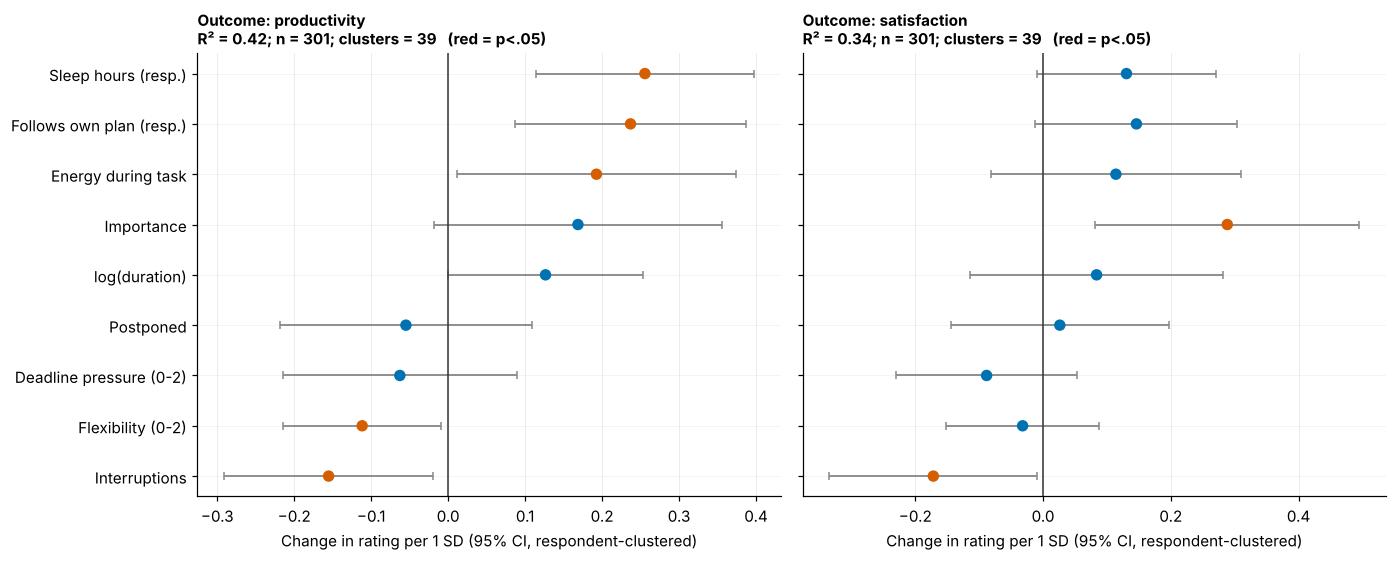

In [30]:
_ = P.fig_forest(fits)

**Reading the results.** Task type and the respondent-level and task-level predictors together explain **42% of the variance in productivity** and **34% in satisfaction** (task-type terms are jointly significant in both). Multicollinearity is not a concern (max VIF = 1.3).
* **Productivity:** the clearest predictors are **sleep hours (+0.26 rating points per SD, 95% CI [0.11, 0.40], Holm p = .007)** and **plan adherence (+0.24, [0.09, 0.39], Holm p = .022)**, the only two that survive Holm correction over the nine predictors. Energy (+0.19), interruptions (-0.16) and flexibility (-0.11) have unadjusted p < .05 but do not survive correction, so treat them as suggestive.
* **Satisfaction:** importance (+0.29, unadjusted p = .008) and interruptions (-0.17, p = .039) are the standouts, but neither survives Holm correction (nine predictors); leisure (+1.1) and sleep (+0.6) are rated more satisfying than assignments, other things equal.
* **Caveats:** (i) the red dots in the forest plot mark *unadjusted* p < .05; (ii) sleep hours and plan adherence are respondent-level traits with only 39 distinct values, and the respondent-level correlation of sleep with overall productivity is ≈ 0 (Section 4.3), so the task-level sleep effect should be considered tentative; (iii) the model is associational.

### 5.4 Chronotype × time of day (exploratory)
**Hypothesis:** tasks done at a time that matches one's chronotype feel more energising and productive (morning types in the morning, evening types at night).
Each report may span several blocks, so we use two indicators, `morning_sched` (early morning or morning) and `night_sched` (night or late night), and test whether their effects **differ by chronotype**
(joint cluster-robust Wald test on the four interaction terms), controlling for task type, since task types differ strongly in both timing and energy (e.g. sleep).

In [31]:
rows, fitsA = [], {}
for y in ["energy", "productivity"]:
    Xa = S.design_matrix(t, numeric=["morning_sched", "night_sched"], categorical=["chronotype", "task"], standardize=False)
    for c in ["morning_sched", "night_sched"]:
        for ch in [n for n in Xa.columns if n.startswith("chronotype_")]:
            Xa[f"{c}:{ch}"] = Xa[c] * Xa[ch]
    f = S.cluster_ols(t[y], Xa, t["row_id"])
    w = S.wald_cluster(f, [n for n in f["names"] if ":" in n])
    rows.append(dict(outcome=y, F=w["F"], df1=w["df1"], df2=w["df2"], p=w["p"], R2=f["r2"]))
    fitsA[y] = f["table"]
al = pd.DataFrame(rows); al["p_holm"] = S.holm(al["p"].values)
for _, row in al.iterrows():
    register("Chronotype x time-of-day (exploratory, Holm, 2 tests)", "Cluster-robust Wald F", row.outcome, "chronotype x morning/night", 301, row.F, f"{int(row.df1)},{int(row.df2)}", row.p, row.R2, "R^2")
save_table(al.set_index("outcome"), "inferential_chronotype_time_alignment")
print(show_p(al.round(3), ["p", "p_holm"]).to_string(index=False))
print("\nEnergy model, interaction terms:")
show_p(fitsA["energy"].loc[[i for i in fitsA["energy"].index if ":" in i]].round(3), ["p"])

     outcome     F  df1  df2    p    R2 p_holm
      energy 1.950    4   38 .122 0.456   .244
productivity 0.868    4   38 .492 0.226   .492

Energy model, interaction terms:


,coef,se,t,p,ci_low,ci_high
morning_sched:chronotype_Evening / night person,0.158,0.226,0.700,.488,-0.300,0.616
morning_sched:chronotype_No clear preference,0.018,0.246,0.075,.941,-0.480,0.517
night_sched:chronotype_Evening / night person,0.013,0.247,0.054,.957,-0.486,0.513
night_sched:chronotype_No clear preference,-0.510,0.242,-2.104,.042,-1.000,-0.019


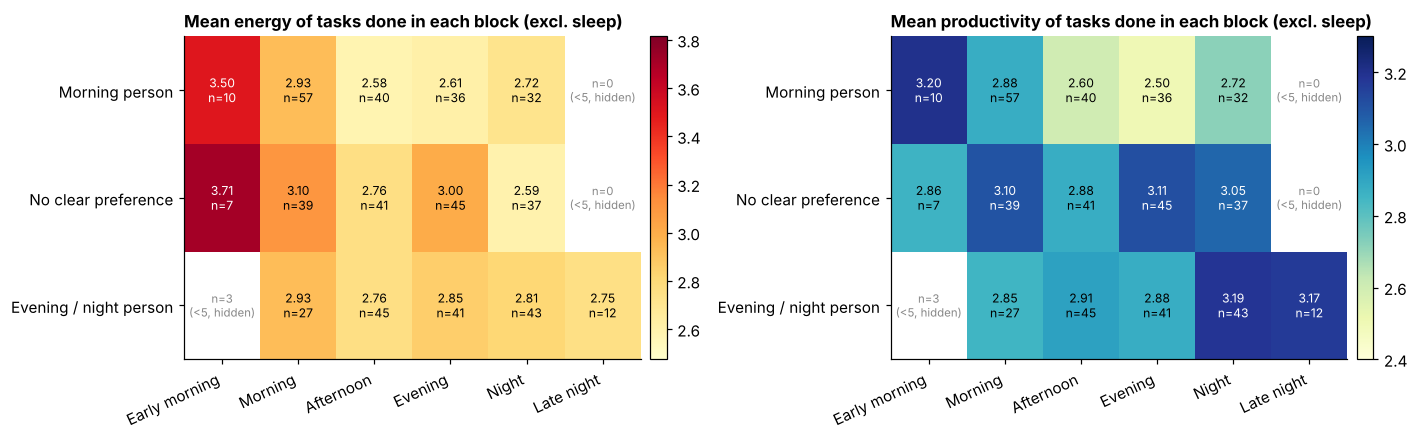

In [32]:
_ = P.fig_chrono_blocks(t)

**Reading the results.** There is **no statistically reliable evidence** that scheduling tasks in line with one's chronotype raises energy or productivity once task type is controlled: the interaction Wald tests give p = .12 (energy; Holm .24) and p = .49 (productivity). The one individually "significant" interaction coefficient (night-scheduled tasks for the *no-clear-preference* group, p = .042) is uncorrected, was not the hypothesised pattern, and is compatible with chance among many coefficients.
The descriptive heatmap is suggestive (morning types rate afternoon/evening tasks as least productive, 2.50-2.60; evening types rate night tasks highest, 3.19), but several cells have few reports (cells with < 5 are hidden) and the formal test does not confirm it. This is a hypothesis for a larger sample.

## 6. Results registry and summary
Every inferential test run in this notebook is stored in one table with Holm-adjusted p-values *within each family*.

In [33]:
reg = pd.DataFrame(REG)
reg["p_holm_within_family"] = reg.groupby("family")["p"].transform(lambda s: S.holm(s.fillna(1.0).values) if s.notna().any() else s)
reg.loc[reg["p"].isna(), "p_holm_within_family"] = np.nan
reg["reject_at_.05"] = reg["p_holm_within_family"] < C.ALPHA
save_table(reg.set_index("family"), "results_registry_all_tests")
print(f"{len(reg)} test records saved to results/tables/results_registry_all_tests.csv")
show_p(reg[reg["reject_at_.05"].fillna(False)][["family", "outcome", "factor", "n", "p", "p_holm_within_family", "effect_size", "effect_name"]].round(3), ["p", "p_holm_within_family"])

72 test records saved to results/tables/results_registry_all_tests.csv


,family,outcome,factor,n,p,p_holm_within_family,effect_size,effect_name
0,Multiple-response items,reasons plans fail,option,39,.002,.002,NaN,
1,Multiple-response items,what decides timing,option,39,< .001,.001,NaN,
4,"Respondent group differences (Holm, 13 tests)",wake_h,chronotype,39,< .001,< .001,0.587,epsilon^2
5,"Respondent group differences (Holm, 13 tests)",bed_h_night,chronotype,39,< .001,< .001,0.710,epsilon^2
8,"Respondent group differences (Holm, 13 tests)",follow_plan,plan_style,39,< .001,.004,0.484,epsilon^2
16,"Respondent correlations (Holm, 28 tests)",follow_plan,overall_productivity,39,< .001,.003,0.582,rho
37,"Respondent correlations (Holm, 28 tests)",wake_h,bed_h_night,39,< .001,< .001,0.845,rho
43,Categorical association,peak band,chronotype,37,.002,.002,0.777,Cramer's V (bias-corrected)
44,"Task-type differences (Holm, 6 tests)",energy,task type,301,< .001,< .001,0.440,epsilon^2 (KW)
45,"Task-type differences (Holm, 6 tests)",productivity,task type,301,< .001,< .001,0.187,epsilon^2 (KW)


### Key findings
1. **Plan adherence is the most robust correlate of productivity.** Respondent-level ρ = 0.58 (Holm p = .003); it also predicts task-level productivity (+0.24 per SD, Holm p = .022). People using a calendar app or time-blocking report much higher plan adherence than non-planners (3.9 vs 2.1).
2. **Chronotype changes *when* people live, not how they perform.** Strong differences in wake/bed time and peak time (ε² = 0.59-0.71; V = 0.78), but no detectable differences in productivity, sleep duration, or plan adherence, and no confirmed benefit of scheduling in line with chronotype.
3. **Task type shapes the day:** energy differs most across tasks (ε² = 0.44); exercise, assignments and study are high-energy, while sleep, leisure and commuting are low-energy. Interruptions are heaviest for study and assignments.
4. **Why plans fail:** phone/social media (46%) leads, followed by procrastination, requests from others and poor time estimation; deadlines (51%) and free time (44%) decide timing more than energy (38%).
5. **Robustness:** conclusions are unchanged after excluding the four flagged respondents.
6. **Null results are informative but low-powered:** academic level, living arrangement, age group and app interest show no detectable relationships with productivity.

## 7. Limitations
* **Small, non-random sample (n = 39).** Quota-like balance means percentages are not population estimates; power is limited, so "no significant difference" is *not* evidence of no difference (see the confidence intervals / effect sizes).
* **Self-report.** Ratings of energy, productivity and satisfaction are subjective and may share a common response style; task-level predictors and outcomes come from the same person at the same time.
* **Ordinal data.** OLS on 1-5 ratings is an approximation; the non-parametric results are the primary evidence at respondent level.
* **Clustered, unbalanced task data.** Handled with cluster-robust inference, but with only 39 clusters CIs are still wide.
* **Sparse variables.** `focus_hours` (13/39 answered) and `times_per_week` (≈51% missing) were not used for inference.
* **Multiplicity.** Holm correction is applied within each family, not across the whole notebook; the exploratory chronotype × time-of-day analysis in particular should be treated as hypothesis-generating.
* **Association, not causation.** The survey is cross-sectional.

## 8. Reproducibility

In [34]:
import importlib.metadata as md_
print("Python   :", platform.python_version())
for pkg in ["numpy", "pandas", "scipy", "matplotlib"]:
    print(f"{pkg:9s}:", md_.version(pkg))
print("Random seed:", C.SEED)
print("Figures written:", len(list(C.FIG_DIR.glob('*.png'))), "| Tables written:", len(list(C.TABLE_DIR.glob('*.csv'))))

Python   : 3.12.3
numpy    : 2.5.4
pandas   : 3.0.6
scipy    : 1.18.1
matplotlib: 3.11.2
Random seed: 20260122
Figures written: 16 | Tables written: 17
